# Step 04 — Baseline Model

**Tujuan:** Melatih model pertama (LightGBM) tanpa resampling sebagai benchmark.

Model ini sengaja **tidak dioptimasi** — kita ingin tahu kemampuan dasarnya sebelum eksperimen lebih lanjut di Notebook 05.

---

## 4.1 Setup

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import joblib
import warnings
warnings.filterwarnings('ignore')

import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
    classification_report, confusion_matrix,
    f1_score, precision_score, recall_score
)

FRAUD_COLOR    = '#E84C4C'
NONFRAUD_COLOR = '#4C9BE8'
SEED = 42

print('Setup done ✓')
print(f'LightGBM version: {lgb.__version__}')

Setup done ✓
LightGBM version: 4.6.0


In [2]:
%%time
df = pd.read_parquet('../data/features/train_features.parquet')
print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols')
print(f'isFraud rate: {df["isFraud"].mean()*100:.2f}%')

Loaded: 590,540 rows × 421 cols
isFraud rate: 3.50%
CPU times: user 975 ms, sys: 939 ms, total: 1.91 s
Wall time: 292 ms


---
## 4.2 Train / Validation Split

In [3]:
DROP_COLS   = ['TransactionID', 'isFraud', 'TransactionDT']
feature_cols = [c for c in df.columns if c not in DROP_COLS]

X = df[feature_cols]
y = df['isFraud']

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print(f'Train : {X_train.shape[0]:,} rows | fraud rate: {y_train.mean()*100:.2f}%')
print(f'Val   : {X_val.shape[0]:,} rows | fraud rate: {y_val.mean()*100:.2f}%')
print(f'Features: {X_train.shape[1]}')

Train : 472,432 rows | fraud rate: 3.50%
Val   : 118,108 rows | fraud rate: 3.50%
Features: 419


---
## 4.3 Train LightGBM Baseline

In [4]:
params = {
    'objective'     : 'binary',
    'metric'        : 'auc',
    'n_estimators'  : 1000,
    'learning_rate' : 0.05,
    'num_leaves'    : 31,
    'max_depth'     : -1,
    'min_child_samples': 20,
    'subsample'     : 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha'     : 0.1,
    'reg_lambda'    : 0.1,
    'random_state'  : SEED,
    'n_jobs'        : -1,
    'verbose'       : -1,
}

print('Parameter baseline:')
for k, v in params.items():
    print(f'  {k:20s}: {v}')

Parameter baseline:
  objective           : binary
  metric              : auc
  n_estimators        : 1000
  learning_rate       : 0.05
  num_leaves          : 31
  max_depth           : -1
  min_child_samples   : 20
  subsample           : 0.8
  colsample_bytree    : 0.8
  reg_alpha           : 0.1
  reg_lambda          : 0.1
  random_state        : 42
  n_jobs              : -1
  verbose             : -1


In [5]:
%%time
model = lgb.LGBMClassifier(**params)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100),
    ]
)

print(f'\nBest iteration: {model.best_iteration_}')

[100]	valid_0's auc: 0.915842


[200]	valid_0's auc: 0.933468


[300]	valid_0's auc: 0.940634


[400]	valid_0's auc: 0.945777


[500]	valid_0's auc: 0.949237


[600]	valid_0's auc: 0.953165


[700]	valid_0's auc: 0.955735


[800]	valid_0's auc: 0.95784


[900]	valid_0's auc: 0.959005


[1000]	valid_0's auc: 0.96089

Best iteration: 1000
CPU times: user 1min 20s, sys: 9.99 s, total: 1min 30s
Wall time: 19.6 s


---
## 4.4 Evaluasi Model

In [6]:
y_prob_train = model.predict_proba(X_train)[:, 1]
y_prob_val   = model.predict_proba(X_val)[:, 1]
y_pred_val   = (y_prob_val >= 0.5).astype(int)

metrics = {
    'AUC-ROC (val)'  : roc_auc_score(y_val, y_prob_val),
    'AUC-PR (val)'   : average_precision_score(y_val, y_prob_val),
    'AUC-ROC (train)': roc_auc_score(y_train, y_prob_train),
    'AUC-PR (train)' : average_precision_score(y_train, y_prob_train),
    'F1 fraud (val)' : f1_score(y_val, y_pred_val),
    'Precision (val)': precision_score(y_val, y_pred_val),
    'Recall (val)'   : recall_score(y_val, y_pred_val),
}

print('=== Baseline Model Metrics ===')
for name, val in metrics.items():
    print(f'  {name:22s}: {val:.4f}')

overfit_gap = metrics['AUC-ROC (train)'] - metrics['AUC-ROC (val)']
print(f'\n  Overfit gap (AUC train-val): {overfit_gap:.4f}')
print('  → Gap <0.02 = bagus, 0.02-0.05 = moderat, >0.05 = overfitting')

=== Baseline Model Metrics ===
  AUC-ROC (val)         : 0.9609
  AUC-PR (val)          : 0.7951
  AUC-ROC (train)       : 0.9829
  AUC-PR (train)        : 0.8860
  F1 fraud (val)        : 0.7001
  Precision (val)       : 0.9423
  Recall (val)          : 0.5570

  Overfit gap (AUC train-val): 0.0220
  → Gap <0.02 = bagus, 0.02-0.05 = moderat, >0.05 = overfitting


In [7]:
print('\nClassification Report (threshold=0.5):')
print(classification_report(y_val, y_pred_val, target_names=['Non-Fraud', 'Fraud'], digits=4))


Classification Report (threshold=0.5):
              precision    recall  f1-score   support

   Non-Fraud     0.9842    0.9988    0.9914    113975
       Fraud     0.9423    0.5570    0.7001      4133

    accuracy                         0.9833    118108
   macro avg     0.9632    0.7779    0.8458    118108
weighted avg     0.9827    0.9833    0.9812    118108



---
## 4.5 Visualisasi Evaluasi

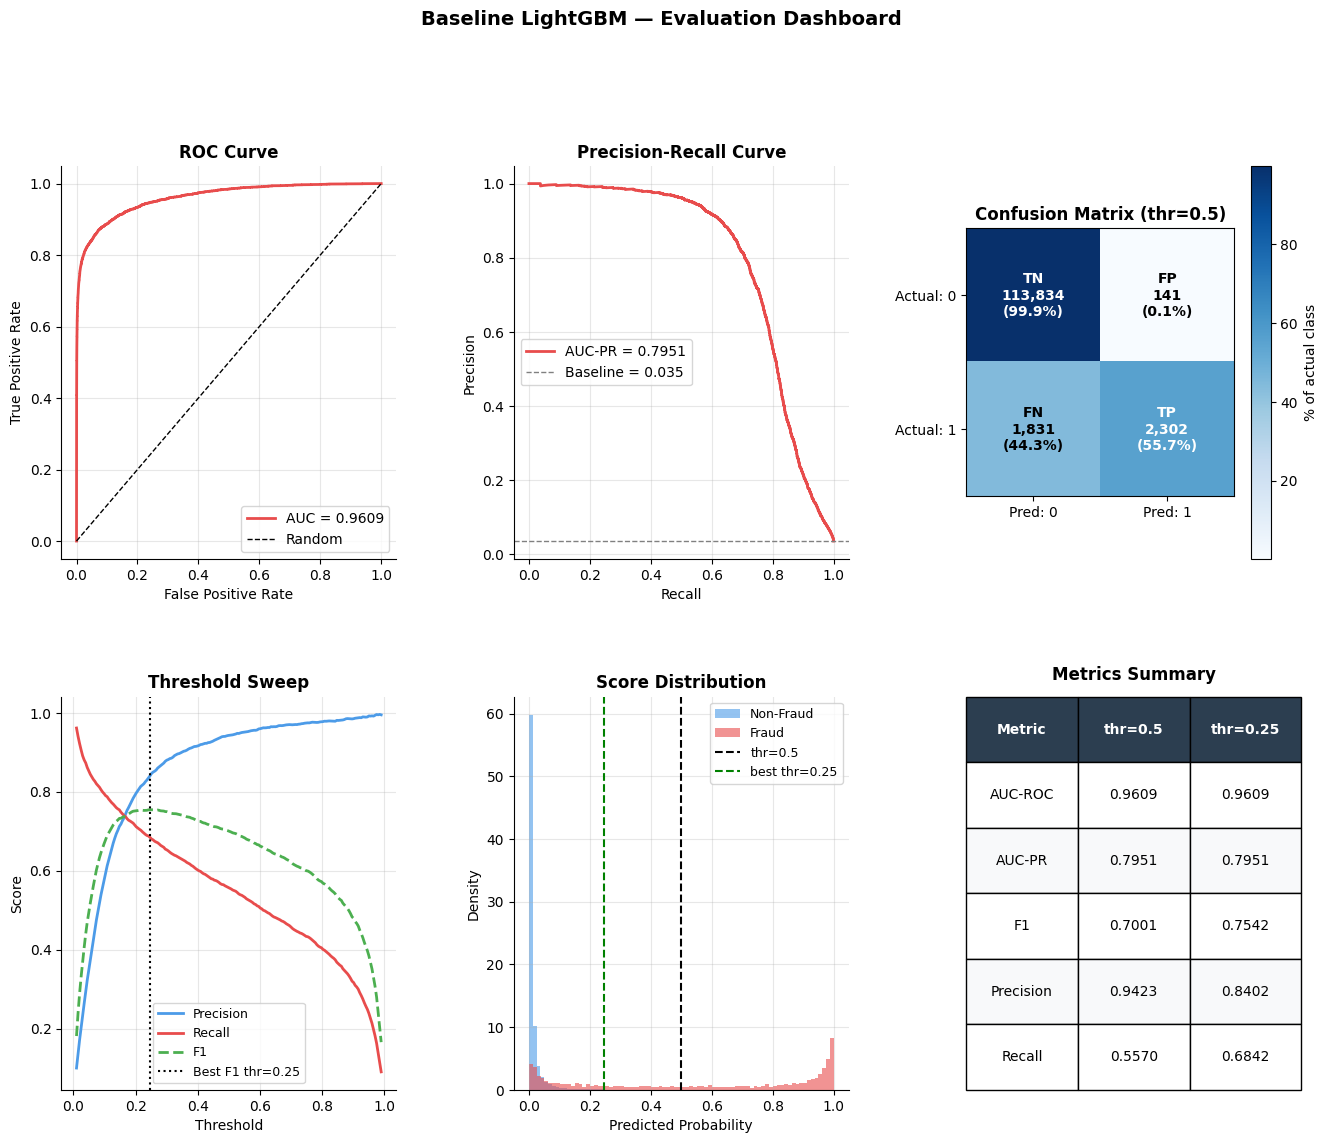


Best threshold (max F1): 0.2464


In [8]:
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.35)

# --- ROC Curve ---
ax1 = fig.add_subplot(gs[0, 0])
fpr, tpr, _ = roc_curve(y_val, y_prob_val)
auc_roc = roc_auc_score(y_val, y_prob_val)
ax1.plot(fpr, tpr, color=FRAUD_COLOR, linewidth=2, label=f'AUC = {auc_roc:.4f}')
ax1.plot([0,1], [0,1], 'k--', linewidth=1, label='Random')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve', fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)
ax1.spines[['top', 'right']].set_visible(False)

# --- PR Curve ---
ax2 = fig.add_subplot(gs[0, 1])
precision_arr, recall_arr, thresholds_pr = precision_recall_curve(y_val, y_prob_val)
auc_pr = average_precision_score(y_val, y_prob_val)
baseline_pr = y_val.mean()
ax2.plot(recall_arr, precision_arr, color=FRAUD_COLOR, linewidth=2, label=f'AUC-PR = {auc_pr:.4f}')
ax2.axhline(baseline_pr, color='grey', linestyle='--', linewidth=1, label=f'Baseline = {baseline_pr:.3f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve', fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)
ax2.spines[['top', 'right']].set_visible(False)

# --- Confusion Matrix ---
ax3 = fig.add_subplot(gs[0, 2])
cm = confusion_matrix(y_val, y_pred_val)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
im = ax3.imshow(cm_pct, cmap='Blues')
labels = [['TN', 'FP'], ['FN', 'TP']]
for i in range(2):
    for j in range(2):
        ax3.text(j, i, f'{labels[i][j]}\n{cm[i,j]:,}\n({cm_pct[i,j]:.1f}%)',
                 ha='center', va='center', fontsize=10, fontweight='bold',
                 color='white' if cm_pct[i,j] > 50 else 'black')
ax3.set_xticks([0,1])
ax3.set_yticks([0,1])
ax3.set_xticklabels(['Pred: 0', 'Pred: 1'])
ax3.set_yticklabels(['Actual: 0', 'Actual: 1'])
ax3.set_title('Confusion Matrix (thr=0.5)', fontweight='bold')
plt.colorbar(im, ax=ax3, label='% of actual class')

# --- Threshold Sweep ---
ax4 = fig.add_subplot(gs[1, 0])
thresholds_sweep = np.linspace(0.01, 0.99, 200)
precisions, recalls, f1s = [], [], []
for thr in thresholds_sweep:
    pred = (y_prob_val >= thr).astype(int)
    if pred.sum() == 0:
        precisions.append(0); recalls.append(0); f1s.append(0)
        continue
    precisions.append(precision_score(y_val, pred, zero_division=0))
    recalls.append(recall_score(y_val, pred, zero_division=0))
    f1s.append(f1_score(y_val, pred, zero_division=0))

best_thr = thresholds_sweep[np.argmax(f1s)]
ax4.plot(thresholds_sweep, precisions, color=NONFRAUD_COLOR, label='Precision', linewidth=2)
ax4.plot(thresholds_sweep, recalls, color=FRAUD_COLOR, label='Recall', linewidth=2)
ax4.plot(thresholds_sweep, f1s, color='#4CAF50', label='F1', linewidth=2, linestyle='--')
ax4.axvline(best_thr, color='black', linestyle=':', linewidth=1.5, label=f'Best F1 thr={best_thr:.2f}')
ax4.set_xlabel('Threshold')
ax4.set_ylabel('Score')
ax4.set_title('Threshold Sweep', fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(alpha=0.3)
ax4.spines[['top', 'right']].set_visible(False)

# --- Score Distribution ---
ax5 = fig.add_subplot(gs[1, 1])
ax5.hist(y_prob_val[y_val==0], bins=80, alpha=0.6, color=NONFRAUD_COLOR,
         label='Non-Fraud', density=True)
ax5.hist(y_prob_val[y_val==1], bins=80, alpha=0.6, color=FRAUD_COLOR,
         label='Fraud', density=True)
ax5.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='thr=0.5')
ax5.axvline(best_thr, color='green', linestyle='--', linewidth=1.5, label=f'best thr={best_thr:.2f}')
ax5.set_xlabel('Predicted Probability')
ax5.set_ylabel('Density')
ax5.set_title('Score Distribution', fontweight='bold')
ax5.legend(fontsize=9)
ax5.grid(alpha=0.3)
ax5.spines[['top', 'right']].set_visible(False)

# --- Metrics Summary ---
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
y_pred_best = (y_prob_val >= best_thr).astype(int)
summary_data = [
    ['Metric', 'thr=0.5', f'thr={best_thr:.2f}'],
    ['AUC-ROC', f'{auc_roc:.4f}', f'{auc_roc:.4f}'],
    ['AUC-PR' , f'{auc_pr:.4f}' , f'{auc_pr:.4f}'],
    ['F1'     , f'{f1_score(y_val, y_pred_val):.4f}',     f'{f1_score(y_val, y_pred_best):.4f}'],
    ['Precision', f'{precision_score(y_val, y_pred_val):.4f}', f'{precision_score(y_val, y_pred_best):.4f}'],
    ['Recall' , f'{recall_score(y_val, y_pred_val):.4f}', f'{recall_score(y_val, y_pred_best):.4f}'],
]
tbl = ax6.table(cellText=summary_data[1:], colLabels=summary_data[0],
                cellLoc='center', loc='center',
                bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2C3E50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#F8F9FA')
ax6.set_title('Metrics Summary', fontweight='bold', pad=12)

plt.suptitle('Baseline LightGBM — Evaluation Dashboard', fontsize=14, fontweight='bold', y=1.01)
plt.savefig('../reports/figures/04_baseline_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nBest threshold (max F1): {best_thr:.4f}')

---
## 4.6 Feature Importance

In [9]:
importance_df = pd.DataFrame({
    'feature'   : feature_cols,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print('Top 20 Features:')
print(importance_df.head(20).to_string(index=False))

Top 20 Features:
                   feature  importance
                     card1        1103
            TransactionAmt        1083
card1_TransactionAmt_count        1041
  card1_TransactionAmt_std         871
 card1_TransactionAmt_mean         830
                     addr1         724
                     card2         680
addr1_TransactionAmt_count         674
card2_TransactionAmt_count         673
 card2_TransactionAmt_mean         651
                       C13         609
 addr1_TransactionAmt_mean         561
  card2_TransactionAmt_std         559
        P_emaildomain_freq         534
                     id_20         531
  addr1_TransactionAmt_std         507
                       D15         503
                        C1         433
                        D1         419
                      hour         385


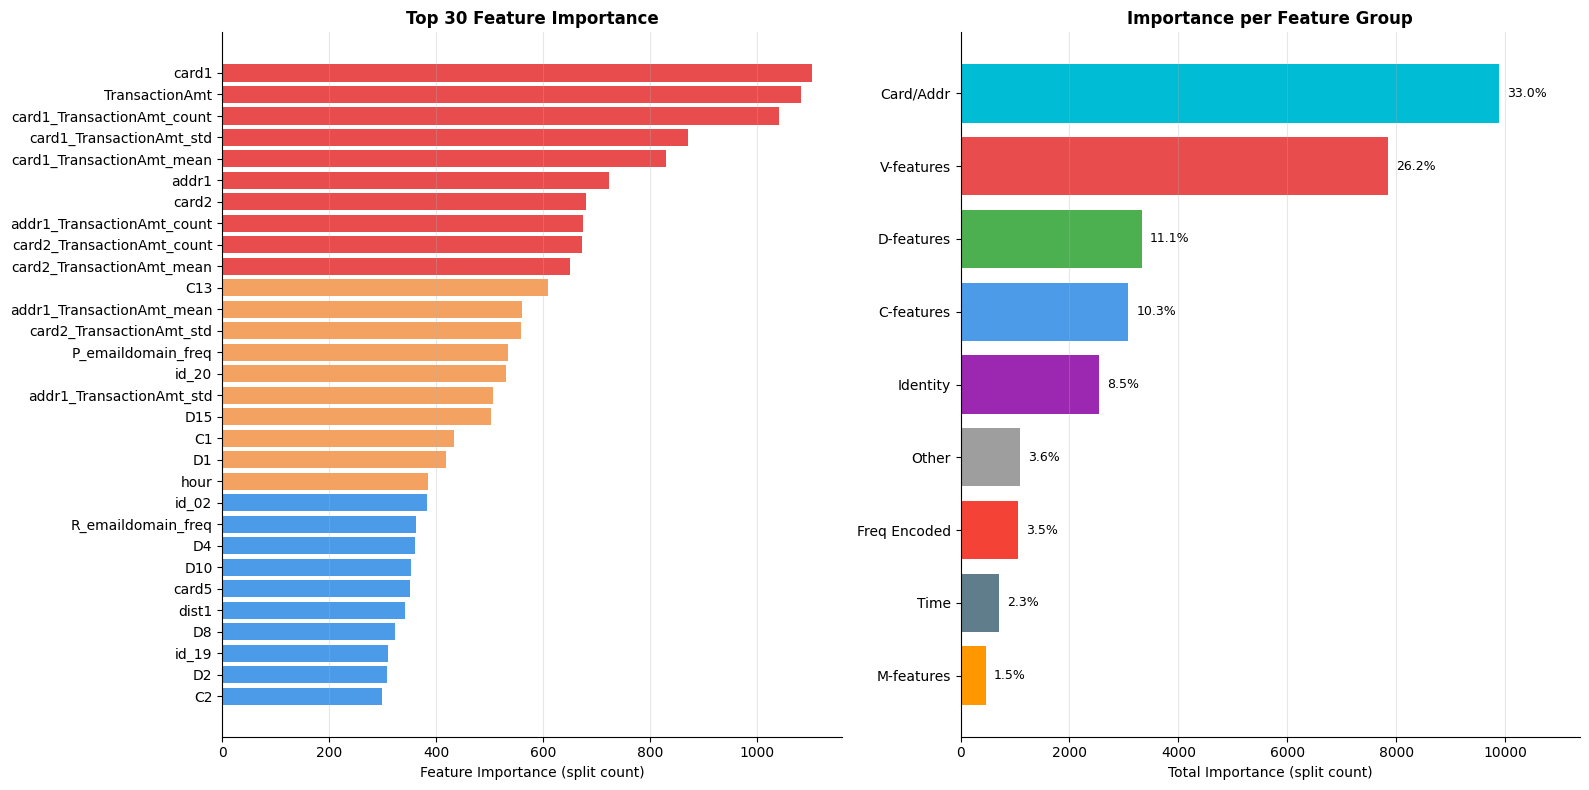

In [10]:
top_n = 30
top_imp = importance_df.head(top_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Bar chart top 30
ax = axes[0]
colors = ['#E84C4C' if i < 10 else '#F4A261' if i < 20 else '#4C9BE8'
          for i in range(len(top_imp))]
ax.barh(top_imp['feature'][::-1], top_imp['importance'][::-1], color=colors[::-1])
ax.set_xlabel('Feature Importance (split count)')
ax.set_title(f'Top {top_n} Feature Importance', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# Importance by feature group
ax = axes[1]
def get_group(col):
    if col.startswith('V'): return 'V-features'
    if col.startswith('C'): return 'C-features'
    if col.startswith('D'): return 'D-features'
    if col.startswith('M'): return 'M-features'
    if col.startswith('id_'): return 'Identity'
    if col.startswith(('card', 'addr', 'dist')): return 'Card/Addr'
    if col.endswith('_freq'): return 'Freq Encoded'
    if any(col.endswith(s) for s in ['_mean', '_std', '_count']): return 'Aggregation'
    if col in ['hour', 'day_of_week', 'is_night', 'is_weekend']: return 'Time'
    return 'Other'

importance_df['group'] = importance_df['feature'].apply(get_group)
group_importance = importance_df.groupby('group')['importance'].sum().sort_values(ascending=True)

group_colors = {
    'V-features': '#E84C4C', 'C-features': '#4C9BE8', 'D-features': '#4CAF50',
    'M-features': '#FF9800', 'Identity': '#9C27B0', 'Card/Addr': '#00BCD4',
    'Freq Encoded': '#F44336', 'Aggregation': '#795548', 'Time': '#607D8B', 'Other': '#9E9E9E'
}
bar_colors = [group_colors.get(g, '#9E9E9E') for g in group_importance.index]
bars = ax.barh(group_importance.index, group_importance.values, color=bar_colors)
total = group_importance.sum()
for bar, val in zip(bars, group_importance.values):
    ax.text(bar.get_width() + total*0.005, bar.get_y() + bar.get_height()/2,
            f'{val/total*100:.1f}%', va='center', fontsize=9)
ax.set_xlabel('Total Importance (split count)')
ax.set_title('Importance per Feature Group', fontweight='bold')
ax.set_xlim(0, group_importance.max() * 1.15)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/04_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4.7 Simpan Model

In [11]:
import json
from pathlib import Path

artifacts_dir = Path('../models/artifacts')
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Simpan model
model_path = artifacts_dir / 'lgbm_baseline.pkl'
joblib.dump(model, model_path)
print(f'Model saved → {model_path}')

# Simpan feature list
feature_list_path = artifacts_dir / 'feature_cols.json'
with open(feature_list_path, 'w') as f:
    json.dump(feature_cols, f)
print(f'Feature list saved → {feature_list_path}')

# Simpan metrics
metrics_to_save = {
    'model'           : 'lgbm_baseline',
    'n_features'      : len(feature_cols),
    'best_iteration'  : int(model.best_iteration_),
    'auc_roc_val'     : round(float(metrics['AUC-ROC (val)']), 4),
    'auc_pr_val'      : round(float(metrics['AUC-PR (val)']), 4),
    'f1_val_thr05'    : round(float(metrics['F1 fraud (val)']), 4),
    'best_thr_f1'     : round(float(best_thr), 4),
    'f1_val_best_thr' : round(float(f1_score(y_val, (y_prob_val >= best_thr).astype(int))), 4),
}

metrics_path = artifacts_dir / 'baseline_metrics.json'
with open(metrics_path, 'w') as f:
    json.dump(metrics_to_save, f, indent=2)

print(f'Metrics saved → {metrics_path}')
print()
print(json.dumps(metrics_to_save, indent=2))

Model saved → ../models/artifacts/lgbm_baseline.pkl
Feature list saved → ../models/artifacts/feature_cols.json
Metrics saved → ../models/artifacts/baseline_metrics.json

{
  "model": "lgbm_baseline",
  "n_features": 419,
  "best_iteration": 1000,
  "auc_roc_val": 0.9609,
  "auc_pr_val": 0.7951,
  "f1_val_thr05": 0.7001,
  "best_thr_f1": 0.2464,
  "f1_val_best_thr": 0.7542
}


---
## 4.8 Analisis Error — Mana yang Salah?

Memahami karakteristik False Negative (fraud yang lolos) dan False Positive (non-fraud yang kena flag).

In [12]:
val_df = X_val.copy()
val_df['y_true'] = y_val.values
val_df['y_prob'] = y_prob_val
val_df['y_pred'] = y_pred_val
val_df['error_type'] = 'TN'
val_df.loc[(val_df['y_true']==1) & (val_df['y_pred']==1), 'error_type'] = 'TP'
val_df.loc[(val_df['y_true']==1) & (val_df['y_pred']==0), 'error_type'] = 'FN'
val_df.loc[(val_df['y_true']==0) & (val_df['y_pred']==1), 'error_type'] = 'FP'

print('Error type distribution:')
print(val_df['error_type'].value_counts().to_string())

print('\nScore distribution per error type:')
print(val_df.groupby('error_type')['y_prob'].describe()[['mean', '50%', 'min', 'max']].to_string())

Error type distribution:
error_type
TN    113834
TP      2302
FN      1831
FP       141

Score distribution per error type:
                mean       50%       min       max
error_type                                        
FN          0.163009  0.117601  0.000486  0.499812
FP          0.694199  0.655343  0.500221  0.997122
TN          0.014183  0.005727  0.000011  0.496212
TP          0.863966  0.928757  0.500278  0.999975


In [13]:
# FN: fraud yang model missed — score-nya rendah
fn_df = val_df[val_df['error_type'] == 'FN'].sort_values('y_prob')
fp_df = val_df[val_df['error_type'] == 'FP'].sort_values('y_prob', ascending=False)

if 'TransactionAmt' in fn_df.columns:
    print(f'False Negatives — TransactionAmt stats:')
    print(fn_df['TransactionAmt'].describe().to_string())
    print(f'\nFalse Positives — TransactionAmt stats:')
    print(fp_df['TransactionAmt'].describe().to_string())

False Negatives — TransactionAmt stats:
count    1831.000000
mean      169.401525
std       266.228418
min         0.292000
25%        46.805500
50%        92.950000
75%       171.000000
max      3081.970000

False Positives — TransactionAmt stats:
count     141.000000
mean      104.551759
std       157.950726
min         3.566000
25%        26.067000
50%        48.855000
75%       107.950000
max      1104.000000


---
## 4.9 Ringkasan Baseline

| Metric | Nilai |
|--------|-------|
| AUC-ROC | — |
| AUC-PR | — |
| F1 (thr=0.5) | — |
| F1 (best thr) | — |

*(diisi otomatis saat notebook dieksekusi)*

**Observasi:**
- Model baseline tanpa resampling punya **recall rendah** karena class imbalance (~3.5% fraud)
- AUC-ROC tinggi, tapi AUC-PR lebih informatif untuk kasus imbalanced
- Banyak FN (fraud yang lolos) dengan score yang sangat rendah → model belum "aware" terhadap pola fraud

**Next step → Notebook 05: Imbalanced Learning** — bandingkan class weighting, undersampling, dan SMOTE